# CIFAR-10 hyperparameter optimization with Optuna

## Objective
This notebook uses Optuna to search for a promising CIFAR-10 convolutional neural network configuration. Each trial samples model architecture and training parameters, trains that candidate for a short fixed run, and returns its evaluation accuracy. Optuna is configured to maximize that score.

The notebook then inspects the saved study, identifies the best recorded trial, and visualizes optimization history and parameter relationships. The next phase is to train a model using the selected hyperparameters.

In [6]:
from data_preprocess import *
from help_utils import *
import optuna
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchmetrics
import optuna
import joblib
from pprint import pprint

device = 'cuda' if torch.cuda.is_available() else 'cpu'
device

'cpu'

In [3]:
from huggingface_hub import login
login()

In [4]:
ds = get_data()

## Dataset and evaluation split

CIFAR-10 is loaded through the project preprocessing helpers. The training loader shuffles training examples; the evaluation loader does not shuffle them.

> **Important evaluation caveat:** `get_train_and_eval_loaders` assigns `dataset['test']` to `valid_ds`, so the objective is repeatedly scored on the official test split. Those scores have therefore influenced hyperparameter selection and should not be presented as an unbiased final test result. For the next phase, create a validation split from `dataset['train']`, tune and select settings on that validation split, and reserve any untouched test set for a final evaluation. Since this study has already used the official test split, an independent holdout would be needed for a fresh unbiased estimate.

In [5]:
def get_train_and_eval_loaders(dataset, batch_size=128):
    train_ds = CIFAR_10(dataset['train'], TRANSFORM)
    valid_ds = CIFAR_10(dataset['test'], TRANSFORM)

    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(valid_ds, batch_size=batch_size, shuffle=False, )

    return train_loader, val_loader

## Flexible CNN candidate model

`FlexibleCNN` builds a variable-depth feature extractor. Each sampled convolutional block applies a convolution, ReLU, and 2×2 max pooling. The number of blocks, filters per block, and kernel sizes vary by trial. The classifier is created dynamically after the first forward pass so its input size matches the feature map; it then applies dropout, a hidden fully connected layer with ReLU, another dropout, and a 10-class output layer.

A dummy 32×32 RGB input is passed through the model before constructing Adam. This materializes the dynamic classifier parameters so the optimizer includes them.

In [7]:
class FlexibleCNN(nn.Module):
    """
    A flexible Convolutional Neural Network with a dynamically created classifier.

    This CNN's architecture is defined by the provided hyperparameters,
    allowing for a variable number of convolutional layers. The classifier
    (fully connected layers) is constructed during the first forward pass
    to adapt to the output size of the convolutional feature extractor.
    """
    
    def __init__(self, n_layers, n_filters, kernel_sizes, dropout_rate, fc_size):
        """
        Initializes the feature extraction part of the CNN.

        Args:
            n_layers: The number of convolutional blocks to create.
            n_filters: A list of integers specifying the number of output
                       filters for each convolutional block.
            kernel_sizes: A list of integers specifying the kernel size for
                          each convolutional layer.
            dropout_rate: The dropout probability to be used in the classifier.
            fc_size: The number of neurons in the hidden fully connected layer.
        """
        super(FlexibleCNN, self).__init__()

        self.dropout_rate = dropout_rate
        self.fc_size = fc_size
        blocks = []
        in_channels = 3 # RGB input

        for i in range(n_layers):
            out_channels = n_filters[i]
            kernel_size = kernel_sizes[i]
            padding_size = (kernel_size - 1) // 2 # Same padding

            block = nn.Sequential(
                nn.Conv2d(in_channels=in_channels, out_channels=out_channels, kernel_size=kernel_size, padding=padding_size),
                nn.ReLU(),
                nn.MaxPool2d(kernel_size=2, stride=2)
            )

            blocks.append(block)
            in_channels = out_channels

        self.features = nn.Sequential(*blocks)

        # The classifier will be initialized dynamically in the forward pass
        self.classifier = None

    def _create_classifier(self, flattened_size, device):
        """
        Dynamically creates and initializes the classifier part of the network.

        This helper method is called during the first forward pass to build the
        fully connected layers based on the feature map size from the
        convolutional base.

        Args:
            flattened_size: The number of input features for the first linear
                            layer, determined from the flattened feature map.
            device: The device to which the new classifier layers should be moved.
        """
        # Define the classifier's architecture
        # Dynamically create the classifier based on the flattened size
        self.classifier = nn.Sequential(
            nn.Dropout(self.dropout_rate),
            nn.Linear(flattened_size, self.fc_size),
            nn.ReLU(inplace=True),
            nn.Dropout(self.dropout_rate),
            nn.Linear(self.fc_size, 10)
        ).to(device)

    def forward(self, x):
        """
        Defines the forward pass of the model.

        Args:
            x: The input tensor of shape (batch_size, channels, height, width).

        Returns:
            The output logits from the classifier.
        """
        # Get the device of the input tensor to ensure consistency
        device = x.device

        # Apply feature extractor
        x = self.features(x)

        # Flatten for the classifier
        flattened = torch.flatten(x, 1)
        flattened_size = flattened.size(1)

        # Dynamically initialize classifier on first forward pass
        if self.classifier is None:
            self._create_classifier(flattened_size, device)

        return self.classifier(flattened)
        
        

## Training and evaluation helpers

`train_epoch` performs the standard training steps: set training mode, move batches to the selected device, compute logits and cross-entropy loss, backpropagate, update weights, and aggregate sample-weighted loss and accuracy. `evaluate_epoch` switches to evaluation mode and disables gradient tracking while calculating loss and classification metrics.

`train_model_with_scheduler` runs the training epochs and steps the scheduler after each epoch. The Optuna objective uses `CosineAnnealingLR`; its epoch-level step does not depend on the metric argument used by `ReduceLROnPlateau`. The objective evaluates each trained candidate once after its 10-epoch training run and returns accuracy to Optuna.

In [ ]:
def train_epoch(model, train_loader, optimizer, loss_fcn, device, pbar, num_classes=10):
    """Trains the model for a single epoch.

    This function iterates over the training dataloader, performs the forward
    and backward passes, updates the model weights, and calculates the loss
    and accuracy for the entire epoch.

    Args:
        model (nn.Module): The PyTorch model to be trained.
        train_dataloader (DataLoader): The DataLoader containing the training data.
        optimizer (optim.Optimizer): The optimizer for updating model weights.
        loss_fcn: The loss function used for training.
        device: The device (e.g., 'cuda' or 'cpu') to perform training on.
        pbar: A progress bar handler object to visualize training progress.
        num_classes (int, optional): The number of classes in the dataset. Defaults to 10.

    Returns:
        tuple: A tuple containing the average loss and accuracy for the epoch.
    """
    # Set the model to training mode...
    model.train()

    # Initialize metrics for the epoch
    running_loss = 0.0
    total_samples = 0

    accuracy_metric = torchmetrics.Accuracy(
        task='multiclass', num_classes=num_classes, average='micro'
    ).to(device)

    for batch_idx, (inputs, labels) in enumerate(train_loader):
        # Update the batch progress bar
        pbar.update_batch(batch_idx + 1)
        # Move input and label tensors to the specified device
        inputs, labels = inputs.to(device), labels.to(device)
        # clear the gradients from the previous iteration
        optimizer.zero_grad()
        # perform the forward pass
        outputs = model(inputs)
        # Calculate the loss
        loss = loss_fcn(outputs, labels)
        # Perform backward pass to compute the gradients
        loss.backward()
        # Update the model's weights
        optimizer.step()

        # Accumulate the loss for the epoch
        running_loss += loss.item() * inputs.size(0)
        # Get the predicted class with the highest score
        _, predicted = outputs.max(1)
        # Update the total number of samples
        total_samples += inputs.size(0)

        # update accuracy
        accuracy_metric.update(outputs, labels)

    # Calculate the average loss and accuracy
    avg_loss = running_loss / total_samples
    accuracy = accuracy_metric.compute().item()

    return avg_loss, accuracy


def evaluate_epoch(model, val_loader, loss_fcn, device, num_classes=10):
    """Evaluates the model's performance on a validation dataset for one epoch.

    This function iterates over the validation dataloader to calculate the
    average loss and accuracy. Gradient computation is disabled for efficiency.

    Args:
        model (nn.Module): The PyTorch model to be evaluated.
        val_loader (DataLoader): The DataLoader containing the validation data.
        loss_fn: The loss function used for evaluation.
        device: The device (e.g., 'cuda' or 'cpu') to perform the evaluation on.
        num_classes (int, optional): The number of classes in the dataset. Defaults to 10.

    Returns:
        tuple: A tuple containing the average loss, accuracy, precision, recall, and F1_Score for the epoch.
    """

    # Set the model to the evaluation mode
    model.eval()

    # Initialize cumulative metrics for the epoch
    total_samples = 0
    running_loss = 0.0

    accuracy_metric = torchmetrics.Accuracy(
        task='multiclass', num_classes=num_classes, average='micro'
    ).to(device)

    precision_metric = torchmetrics.Precision(
       task='multiclass', num_classes=num_classes, average='macro'
    ).to(device)

    recall_metric = torchmetrics.Recall(
        task='multiclass', num_classes=num_classes, average='macro'
    ).to(device)

    f1_metric = torchmetrics.F1Score(
        task='multiclass', num_classes=num_classes, average='macro'
    ).to(device)

    pbar = NestedProgressBar(total_batches=len(val_loader), mode='eval', total_epochs=1)

    # Disable gradient computation for evaluation
    with torch.no_grad():
        for batch_idx, (inputs, labels) in enumerate(val_loader):
            # Update the progress bar for epoch
            pbar.update_batch(batch_idx + 1)
            # Move input and label tensors to the specified device
            inputs, labels = inputs.to(device), labels.to(device)
            # Perform forward pass to compute the outputs
            outputs = model(inputs)
            # Calculate the loss
            loss = loss_fcn(outputs, labels)

            # Accumulate the total loss
            running_loss += loss.item() * inputs.size(0)
            # Get the predicted class
            _, predicted = outputs.max(1)

            # Update the evaluation metrics
            accuracy_metric.update(outputs, labels)
            precision_metric.update(outputs, labels)
            recall_metric.update(outputs, labels)
            f1_metric.update(outputs, labels)

            total_samples += inputs.size(0)

        # Calculate the average loss and evaluation metrics
        avg_loss = running_loss / total_samples
        acc = accuracy_metric.compute().item()
        prec = precision_metric.compute().item()
        recall = recall_metric.compute().item()
        f1_score = f1_metric.compute().item()

        pbar.close()
        return avg_loss, acc, prec, recall, f1_score

In [8]:
def train_model_with_scheduler(model, optimizer, train_loader, loss_fcn, scheduler, device, n_epochs=25):
    """
    Orchestrates the training of a model for a specified number of epochs.

    This function manages the overall training loop. It initializes a progress
    bar to visualize progress and, for each epoch, calls a helper function
    to perform the actual training steps. It also handles periodic logging
    of the training loss.

    Args:
        model: The neural network model to be trained.
        optimizer: The optimization algorithm (e.g., Adam, SGD).
        loss_fcn: The loss function used for training.
        train_dataloader: The DataLoader providing the training data.
        device: The device ('cpu' or 'cuda') to perform training on.
        n_epochs: The total number of epochs to train the model.
    """

    # Initialize the progress bar
    pbar = NestedProgressBar(
        total_epochs=n_epochs,
        mode='train',
        total_batches=len(train_loader),
        epoch_message_freq=5
    )

    for epoch in range(n_epochs):
        # update the progress bar for the current epoch
        pbar.update_epoch(epoch + 1)

        # Train the model for one epoch
        train_loss, train_acc = train_epoch(model, train_loader, optimizer, loss_fcn, device, pbar)

        # Retrieve the current learning rate from the scheduler
        current_lr = scheduler.get_last_lr()[0]

        # Update the learning rate based on the scheduler type
        if isinstance(scheduler, torch.optim.lr_scheduler.ReduceLROnPlateau):
            scheduler.step(train_acc)
        else:
            scheduler.step()

        # Log the training metrics for the current epoch, including the learning rate
        pbar.maybe_log_epoch(epoch=epoch+1, message=f"At epoch {epoch+1}: Training loss: {train_loss:.4f}, Training accuracy: {train_acc:.4f}, LR: {current_lr:.6f}")

    pbar.close("Training Complete")

## Optuna objective and search space

For every trial, the objective samples:

- Convolutional depth: 1–3 layers.
- Filters per layer: 16–128, with one value per sampled layer.
- Kernel size per layer: 3 or 5.
- Dropout probability: 0.1–0.5.
- Fully connected width: 64–256.
- Adam learning rate: `1e-4`–`1e-2`, sampled on a logarithmic scale.

The batch size (128), training duration (10 epochs), loss (`CrossEntropyLoss`), optimizer family (Adam), and cosine scheduler settings (`T_max=10`, `eta_min=0.0002`) are held fixed. The objective returns evaluation accuracy, and the study direction is maximization. Because the architecture choices are conditional on the sampled number of layers, only the active layers have corresponding filter and kernel parameters.

In [10]:
def objective(trial, device):
    """
    Defines the objective function for hyperparameter optimization using Optuna.

    For each trial, this function samples a set of hyperparameters,
    constructs a model, trains it for a fixed number of epochs, evaluates
    its performance on a validation set, and returns the accuracy. Optuna
    uses the returned accuracy to guide its search for the best
    hyperparameter combination.

    Args:
        trial: An Optuna `Trial` object, used to sample hyperparameters.
        device: The device ('cpu' or 'cuda') for model training and evaluation.

    Returns:
        The validation accuracy of the trained model as a float.
    """

    # Sample hyperparameters for the feature extractor using the Optuna trial

    n_layers = trial.suggest_int("n_layers", 1, 3)
    n_filters = [trial.suggest_int(f"n_filters_{i}", 16, 128) for i in range(n_layers)]
    kernel_sizes = [trial.suggest_categorical(f"kernel_sizes_{i}", [3, 5]) for i in range(n_layers)]

    dropout_rate = trial.suggest_float("dropout_rate", 0.1, 0.5)
    fc_size = trial.suggest_int("fc_size", 64, 256)

    learning_rate = trial.suggest_float("learning_rate", 1e-4, 1e-2, log=True)

    # Instantiate the model with the sampled hyperparameters
    model = FlexibleCNN(n_layers, n_filters, kernel_sizes, dropout_rate, fc_size).to(device)

    # Initialize the dynamic classifier layer by passing a dummy input through the model
    # This ensures all parameters are instantiated before the optimizer is defined
    dummy_input = torch.randn(1, 3, 32, 32).to(device)
    model(dummy_input)

    # Define fixed training parameters:loss function, and optimizer
    loss_fcn = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)



    # Define fixed data loading parameters and create data loaders
    batch_size = 128
    train_loader, val_loader = get_train_and_eval_loaders(ds, batch_size)

    # Define the fixed number of epochs for training & train the model
    n_epochs = 10
    scheduler_cosine = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=n_epochs, eta_min =0.0002)
    train_model_with_scheduler(
        model,
        optimizer,
        train_loader,
        loss_fcn,
        scheduler_cosine,
        device,
        n_epochs
    )

    # Evaluate the trained model's accuracy on the validation set
    _, accuracy, _, _, _ = evaluate_epoch(model, val_loader, loss_fcn, device, 10)

    return accuracy

## Running and loading the study

The study is created with `direction='maximize'`; the code cell sets `n_trials = 20`. A later cell loads `optuna_study.pkl` into `loaded_study`, and the dataframe, best-trial report, and plots are generated from that loaded object. Keep the live `study` and saved `loaded_study` synchronized when continuing a search; the displayed results describe the saved object, not automatically whichever study was most recently created in memory.

In [ ]:
# Create a study object and optimize the objective function
study = optuna.create_study(direction='maximize') # The goal in this case is to maximize accuracy
n_trials = 20
study.optimize(lambda trial: objective(trial, device), n_trials)

In [2]:
# To load the study later, uncomment and run this code:
loaded_study = joblib.load("optuna_study.pkl")
# print(f"Loaded study. Best trial value: {loaded_study.best_trial.value:.4f}")

## Recorded trial table

The table below is from `loaded_study.trials_dataframe()`. In the notebook output it contains trial numbers 0–11 in the `COMPLETE` state and trial 12 in the `FAIL` state: that is 12 completed trials plus one failed trial. This does not match the stated count of 11 completed trials, and the run cell requests 20 trials. Confirm which saved study/output is the intended final record before reporting the trial count. Failed trials have no objective value and are not candidates for the best configuration.

In [3]:
df = loaded_study.trials_dataframe()
df

,number,value,datetime_start,datetime_complete,duration,params_dropout_rate,params_fc_size,params_kernel_sizes_0,params_kernel_sizes_1,params_kernel_sizes_2,params_learning_rate,params_n_filters_0,params_n_filters_1,params_n_filters_2,params_n_layers,system_attrs_tpe:relative_params:0,state
0,0,0.7184,2026-11-14 21:50:46.230621,2026-11-14 21:58:40.883752,0 days 00:07:54.653131,0.306323,182,5,3.0,5.0,0.000299,17,50.0,108.0,3,NaN,COMPLETE
1,1,0.6077,2026-11-14 21:58:40.885102,2026-11-14 22:06:29.849907,0 days 00:07:48.964805,0.447137,170,5,3.0,5.0,0.000115,61,30.0,22.0,3,NaN,COMPLETE
2,2,0.5339,2026-11-14 22:06:29.851045,2026-11-14 22:14:59.045565,0 days 00:08:29.194520,0.140274,253,3,5.0,3.0,0.007404,71,86.0,109.0,3,NaN,COMPLETE
3,3,0.7762,2026-11-14 22:14:59.046789,2026-11-14 22:24:08.121251,0 days 00:09:09.074462,0.104723,113,5,5.0,5.0,0.001012,95,111.0,44.0,3,NaN,COMPLETE
4,4,0.6927,2026-11-14 22:24:08.122313,2026-11-14 22:31:43.734325,0 days 00:07:35.612012,0.234384,161,3,3.0,3.0,0.000292,41,24.0,73.0,3,NaN,COMPLETE
5,5,0.1000,2026-11-14 22:31:43.736214,2026-11-14 22:39:20.700158,0 days 00:07:36.963944,0.103219,123,5,3.0,NaN,0.008732,42,55.0,NaN,2,NaN,COMPLETE
6,6,0.7476,2026-11-14 22:39:20.702969,2026-11-14 22:48:03.258007,0 days 00:08:42.555038,0.203754,209,3,5.0,NaN,0.001050,86,126.0,NaN,2,NaN,COMPLETE
7,7,0.2149,2026-11-14 22:48:03.259097,2026-11-14 22:55:31.923418,0 days 00:07:28.664321,0.440161,120,3,NaN,NaN,0.009793,86,NaN,NaN,1,NaN,COMPLETE
8,8,0.5286,2026-11-14 22:55:31.925860,2026-11-14 23:03:15.782560,0 days 00:07:43.856700,0.464389,166,5,NaN,NaN,0.004292,85,NaN,NaN,1,NaN,COMPLETE
9,9,0.7233,2026-11-14 23:03:15.783804,2026-11-14 23:11:51.466639,0 days 00:08:35.682835,0.456384,82,5,5.0,NaN,0.000290,124,55.0,NaN,2,NaN,COMPLETE


## Best recorded configuration

The loaded study reports trial 3 as best, with an evaluation accuracy of 0.7762 (77.62%). Its sampled settings are 3 convolutional layers; filter widths 95, 111, and 44; kernel sizes 5, 5, and 5; dropout 0.1047; fully connected width 113; and Adam learning rate approximately 0.0010123. The cosine schedule and 10-epoch training duration were fixed across trials, so they are not part of this trial’s sampled parameter dictionary.

This is the best score among the trials recorded in the loaded study, not yet a final model result. Each candidate received only 10 epochs, and the evaluation split is currently the official test split.

In [7]:
# Extract and print the best trial
best_trial = loaded_study.best_trial

print("Best Trial: ")
print(f"   Value (accuracy): {best_trial.value:.4f}")

print("    Hyperparameters: ")
pprint(best_trial.params)

Best Trial: 
   Value (accuracy): 0.7762
    Hyperparameters: 
{'dropout_rate': 0.10472334127295323,
 'fc_size': 113,
 'kernel_sizes_0': 5,
 'kernel_sizes_1': 5,
 'kernel_sizes_2': 5,
 'learning_rate': 0.0010123371968112076,
 'n_filters_0': 95,
 'n_filters_1': 111,
 'n_filters_2': 44,
 'n_layers': 3}


## Interpreting the Optuna visualizations

The optimization-history plot shows each trial’s objective value and how the best score evolves. Parameter-importance estimates summarize which searched parameters were most associated with score variation in this study; with a small number of completed trials, treat them as tentative. The parallel-coordinate plot shows combinations of selected parameters alongside trial outcomes and can help spot promising regions for a follow-up search.

C:\Users\hkame\AppData\Local\Temp\ipykernel_28108\782858301.py:2: ExperimentalWarning: optuna.visualization.matplotlib._optimization_history.plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  optuna.visualization.matplotlib.plot_optimization_history(loaded_study)


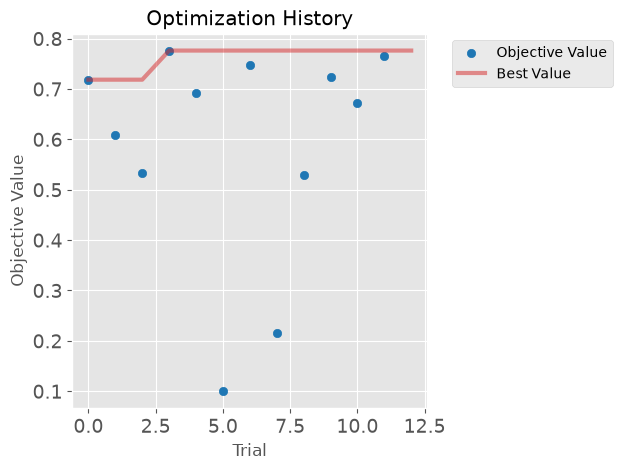

C:\Users\hkame\AppData\Local\Temp\ipykernel_28108\782858301.py:7: ExperimentalWarning: optuna.visualization.matplotlib._param_importances.plot_param_importances is experimental (supported from v2.2.0). The interface can change in the future.
  optuna.visualization.matplotlib.plot_param_importances(loaded_study)


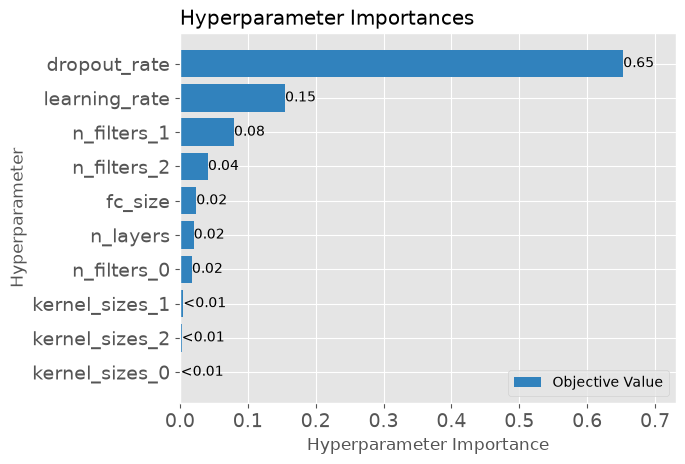

C:\Users\hkame\AppData\Local\Temp\ipykernel_28108\782858301.py:10: ExperimentalWarning: optuna.visualization.matplotlib._parallel_coordinate.plot_parallel_coordinate is experimental (supported from v2.2.0). The interface can change in the future.
  ax = optuna.visualization.matplotlib.plot_parallel_coordinate(


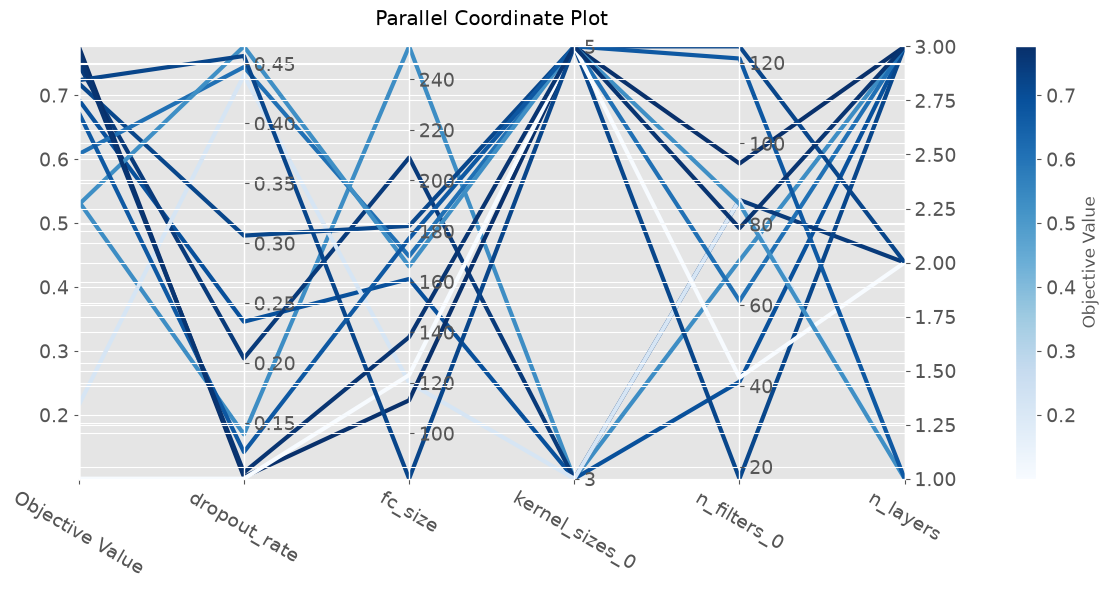

In [9]:
# Plotting the optimization history
optuna.visualization.matplotlib.plot_optimization_history(loaded_study)
plt.title('Optimization History')
plt.show()

# Importance of hyperparameters
optuna.visualization.matplotlib.plot_param_importances(loaded_study)
plt.show()

ax = optuna.visualization.matplotlib.plot_parallel_coordinate(
    loaded_study, params=['n_layers', 'n_filters_0', 'kernel_sizes_0', 'dropout_rate', 'fc_size']
)
fig = ax.figure
fig.set_size_inches(12, 6, forward=True)  # forward=True updates the canvas
fig.tight_layout()

# Conclusion and next step

Optuna explored a flexible CNN search space covering network depth, filters, convolution kernel sizes, dropout, classifier width, and Adam’s learning rate. The saved study output reports 12 completed trials and one failed trial, although the reported count is 11 trials and the run cell requests 20; verify the intended study record before publishing the count. The best recorded trial achieved 77.62% evaluation accuracy after 10 epochs, with a three-layer CNN (95, 111, 44 filters), 5×5 kernels, dropout 0.1047, a 113-unit classifier layer, and learning rate 0.0010123.

**Next step:** instantiate a fresh model with those best-trial settings and train it for the planned full training schedule using Adam and cosine annealing. Before doing so, create a proper validation split from the training data; this notebook used the official test split during optimization, so its 77.62% score is not an unbiased final test result. Use validation data for any further decisions, then evaluate on an untouched holdout once at the end.